# PYTORCH MASTERY — NOTEBOOK 7
## Chapters 32–38: Training Diagnostics → Debugging Neural Networks → TensorBoard/Experiment Tracking → CNN Fundamentals → CNN From Scratch → Computer Vision Pipeline → Transfer Learning

Continuing directly from Notebook 6. This is where the course moves into computer vision.


### PYTORCH MASTERY PROGRESS
Current Chapter: 38 | Current Level: Computer Vision

- [x] Chapters 1–31 *(Notebooks 1–6)*
- [x] Training Diagnostics
- [x] Debugging Neural Networks
- [x] TensorBoard/Experiment Tracking
- [x] CNN Fundamentals
- [x] CNN From Scratch
- [x] Computer Vision Pipeline
- [x] Transfer Learning


---
# CHAPTER 32 — TRAINING DIAGNOSTICS

## 1. Concept
Reading a training run's learning curves correctly — and knowing what additional diagnostics to check beyond just loss — is the core skill for understanding *why* a model is or isn't learning well, directly extending the `history` dict Chapter 23's `train_model()` function already returns.

## 2. The Four Classic Learning Curve Patterns


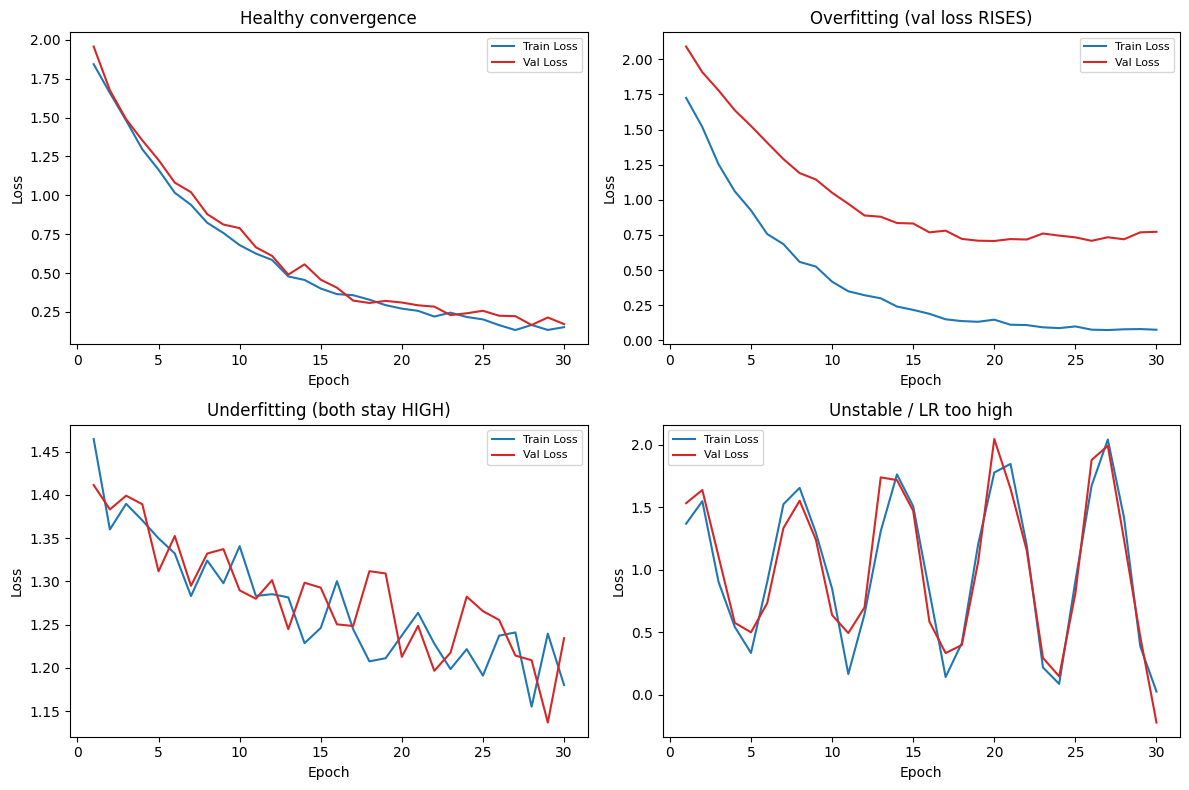

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Simulated (illustrative) training histories for four classic patterns
epochs = np.arange(1, 31)

patterns = {
    "Healthy convergence": {
        "train": 2.0 * np.exp(-epochs / 8) + 0.1 + np.random.normal(0, 0.02, 30),
        "val":   2.0 * np.exp(-epochs / 8) + 0.15 + np.random.normal(0, 0.03, 30),
    },
    "Overfitting (val loss RISES)": {
        "train": 2.0 * np.exp(-epochs / 6) + 0.05 + np.random.normal(0, 0.02, 30),
        "val":   2.0 * np.exp(-epochs / 10) + 0.3 + 0.02 * np.maximum(epochs - 12, 0) + np.random.normal(0, 0.02, 30),
    },
    "Underfitting (both stay HIGH)": {
        "train": 1.5 - 0.3 * np.log1p(epochs) / np.log1p(30) + np.random.normal(0, 0.03, 30),
        "val":   1.5 - 0.28 * np.log1p(epochs) / np.log1p(30) + np.random.normal(0, 0.03, 30),
    },
    "Unstable / LR too high": {
        "train": 1.0 + 0.5 * np.sin(epochs) * np.exp(epochs / 40) + np.random.normal(0, 0.1, 30),
        "val":   1.0 + 0.5 * np.sin(epochs) * np.exp(epochs / 40) + np.random.normal(0, 0.15, 30),
    },
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (name, curves) in zip(axes.flatten(), patterns.items()):
    ax.plot(epochs, curves["train"], label="Train Loss", color="tab:blue")
    ax.plot(epochs, curves["val"], label="Val Loss", color="tab:red")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


### Reading Each Pattern
| Pattern | Diagnosis | Fix |
|---|---|---|
| **Healthy convergence** | Both curves decrease and roughly track each other, with a small, stable gap | Nothing to fix — keep training or fine-tune further |
| **Overfitting** (train ↓, val eventually ↑) | Model is memorizing training-set specifics rather than generalizing — directly analogous to the Scikit-learn course's high-variance learning-curve pattern | More regularization (Ch 31), more data, a smaller model, or early stopping right before the val curve turns upward |
| **Underfitting** (both curves stay high, plateau early) | Model lacks capacity, or hasn't trained long enough, or the learning rate is too conservative | A larger/deeper model, train longer, increase learning rate, reduce excessive regularization |
| **Unstable / LR too high** | Loss oscillates wildly or diverges, sometimes with sudden spikes | Reduce the learning rate; check for exploding gradients (Ch 14, 33) via gradient clipping (Ch 77) |

## 3. Beyond Loss Curves — Gradient Norm and Weight Statistics


In [ ]:
import torch
import torch.nn as nn

model = nn.Sequential(nn.Linear(20, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 2))
x = torch.randn(16, 20)
y = torch.randint(0, 2, (16,))
criterion = nn.CrossEntropyLoss()

logits = model(x)
loss = criterion(logits, y)
loss.backward()

print("=== Gradient norm per layer -- a genuinely useful diagnostic ===")
for name, param in model.named_parameters():
    if param.grad is not None and "weight" in name:
        grad_norm = param.grad.norm().item()
        weight_norm = param.norm().item()
        print(f"{name:<20} grad_norm={grad_norm:.4f}  weight_norm={weight_norm:.4f}  ratio={grad_norm/weight_norm:.4f}")

print("""
Interpreting this table:
  - Gradient norms near ZERO across MULTIPLE layers -> vanishing gradients (Ch 14) --
    those layers are barely updating at all.
  - Gradient norms EXTREMELY large (or NaN) -> exploding gradients -- a strong signal
    to apply gradient clipping (Ch 77) or reduce the learning rate.
  - A HEALTHY training run typically shows gradient norms of a similar ORDER OF
    MAGNITUDE across layers, neither vanishing nor exploding.
""")


=== Gradient norm per layer -- a genuinely useful diagnostic ===
0.weight             grad_norm=0.0979  weight_norm=4.5081  ratio=0.0217
2.weight             grad_norm=0.2131  weight_norm=3.2634  ratio=0.0653
4.weight             grad_norm=0.2060  weight_norm=0.7865  ratio=0.2619

Interpreting this table:
  - Gradient norms near ZERO across MULTIPLE layers -> vanishing gradients (Ch 14) --
    those layers are barely updating at all.
  - Gradient norms EXTREMELY large (or NaN) -> exploding gradients -- a strong signal
    to apply gradient clipping (Ch 77) or reduce the learning rate.
  - A HEALTHY training run typically shows gradient norms of a similar ORDER OF
    MAGNITUDE across layers, neither vanishing nor exploding.



### Common Mistakes
- Only ever looking at the final loss number, never the full curve shape across epochs — misses genuinely diagnostic information about *when* and *how* a problem developed.
- Diagnosing overfitting purely from a single epoch's train/val gap, rather than the *trend* over time — a persistently small gap that's stable is very different from a small gap that's steadily widening.
- Not checking gradient norms when a model "isn't learning" — jumping straight to architecture changes without first confirming whether gradients are even flowing in a healthy range at all.

### Interview Insight
**Q: Your model's training loss decreases smoothly, but validation loss decreases initially then starts rising around epoch 15. What's your diagnosis and your first two things to try?**
A: This is the classic overfitting signature — the model continues improving on training data (which it can effectively memorize, given enough capacity/epochs) while genuinely losing generalization ability on unseen validation data past epoch 15. My first two interventions: add or increase regularization (Dropout probability, weight decay — Chapter 31) since it's often the cheapest, lowest-risk change to an existing architecture; and set up early stopping with checkpointing (Chapter 31, 70) to automatically capture and retain the model state from right around epoch 15 (or wherever validation loss was actually minimized), rather than continuing to train — and inevitably overfit further — past that point.

### Exercise
1. Given a `history` dict from Chapter 23's `train_model()`, write a function that automatically classifies the run into one of this chapter's four patterns based on the shape of the train/val curves.
2. Compute and print gradient norms for every layer of a small network after one backward pass, and identify whether any layer looks concerningly small or large relative to the others.

### Quiz (Chapter 32)
1. Match each of the 4 learning curve patterns to its most likely fix.
2. What does a near-zero gradient norm across multiple layers suggest?
3. Why is looking at the trend over epochs more informative than a single epoch's train/val gap?


---
# CHAPTER 33 — DEBUGGING NEURAL NETWORKS

## Concept
A consolidated debugging reference for the most common PyTorch training failures, following the `Problem → Error → Cause → Diagnosis → Fix → Prevention` structure established throughout this course.


In [ ]:
import torch
import torch.nn as nn

# === Problem 1: Shape mismatch ===
model = nn.Linear(10, 5)
try:
    model(torch.randn(32, 20))   # wrong input feature dimension
except RuntimeError as e:
    print("Problem 1 -- Shape mismatch:")
    print(" ", str(e)[:150])
    print("  CAUSE: input's last dimension (20) doesn't match nn.Linear's in_features (10).")
    print("  FIX: check .shape at every stage of the pipeline; print shapes liberally while debugging.")


Problem 1 -- Shape mismatch:
  mat1 and mat2 shapes cannot be multiplied (32x20 and 10x5)
  CAUSE: input's last dimension (20) doesn't match nn.Linear's in_features (10).
  FIX: check .shape at every stage of the pipeline; print shapes liberally while debugging.


In [ ]:
# === Problem 2: Wrong target dtype for CrossEntropyLoss ===
criterion = nn.CrossEntropyLoss()
logits = torch.randn(4, 3)
wrong_targets = torch.tensor([0.0, 1.0, 2.0, 0.0])   # FLOAT, should be int64
try:
    criterion(logits, wrong_targets)
except RuntimeError as e:
    print("\nProblem 2 -- Wrong target dtype:")
    print(" ", str(e)[:150])
    print("  FIX: targets = targets.long()  (Chapter 19)")



Problem 2 -- Wrong target dtype:
  expected scalar type Long but found Float
  FIX: targets = targets.long()  (Chapter 19)


In [ ]:
# === Problem 3: NaN loss ===
print("""
Problem 3 -- NaN loss (appears partway through training, or immediately):

  CAUSE (most common, in order of likelihood):
    1. Learning rate too high -> exploding gradients/weights (Ch 14, 32)
    2. log(0) or division by zero somewhere (e.g., manual log-probability computation
       without adequate numerical safeguards -- prefer built-in fused losses, Ch 19)
    3. Bad/corrupted input data (an actual NaN or Inf value in your dataset itself)
    4. float16 training WITHOUT GradScaler (Ch 4, 29 -- overflow)

  DIAGNOSIS:
    - Check input data for NaN/Inf FIRST: torch.isnan(x).any(), torch.isinf(x).any()
    - Check gradient norms (Ch 32) right before the NaN appears -- were they exploding?
    - Try a MUCH smaller learning rate temporarily -- if NaN disappears, LR was the cause.

  FIX: reduce learning rate, add gradient clipping (Ch 77), verify data integrity,
  ensure GradScaler is used with float16 mixed precision.
""")



Problem 3 -- NaN loss (appears partway through training, or immediately):

  CAUSE (most common, in order of likelihood):
    1. Learning rate too high -> exploding gradients/weights (Ch 14, 32)
    2. log(0) or division by zero somewhere (e.g., manual log-probability computation
       without adequate numerical safeguards -- prefer built-in fused losses, Ch 19)
    3. Bad/corrupted input data (an actual NaN or Inf value in your dataset itself)
    4. float16 training WITHOUT GradScaler (Ch 4, 29 -- overflow)

  DIAGNOSIS:
    - Check input data for NaN/Inf FIRST: torch.isnan(x).any(), torch.isinf(x).any()
    - Check gradient norms (Ch 32) right before the NaN appears -- were they exploding?
    - Try a MUCH smaller learning rate temporarily -- if NaN disappears, LR was the cause.

  FIX: reduce learning rate, add gradient clipping (Ch 77), verify data integrity,
  ensure GradScaler is used with float16 mixed precision.



In [ ]:
# === Problem 4: Model not learning at all (loss flat, near-random accuracy) ===
print("""
Problem 4 -- Model not learning (loss stays flat, accuracy near chance level):

  CAUSE (checklist, in order of likelihood):
    1. Learning rate too LOW -- updates are happening but imperceptibly small
    2. Forgot optimizer.zero_grad() -- gradients accumulating incorrectly (Ch 15)
    3. Layers defined INSIDE forward() instead of __init__() -- never actually
       registered as trainable parameters (Ch 16)
    4. Loss function/activation mismatch (softmax before CrossEntropyLoss, Ch 19)
    5. Labels are WRONG or shuffled inconsistently relative to their features
    6. requires_grad accidentally False on model parameters (rare, but possible after
       certain manual tensor manipulations)

  DIAGNOSIS: print model.parameters() gradient norms after one backward() call --
  if ALL are exactly zero, something upstream is fundamentally broken (likely #2 or #3).
  If gradients look reasonable but loss still doesn't improve, suspect #1, #4, or #5.
""")



Problem 4 -- Model not learning (loss stays flat, accuracy near chance level):

  CAUSE (checklist, in order of likelihood):
    1. Learning rate too LOW -- updates are happening but imperceptibly small
    2. Forgot optimizer.zero_grad() -- gradients accumulating incorrectly (Ch 15)
    3. Layers defined INSIDE forward() instead of __init__() -- never actually
       registered as trainable parameters (Ch 16)
    4. Loss function/activation mismatch (softmax before CrossEntropyLoss, Ch 19)
    5. Labels are WRONG or shuffled inconsistently relative to their features
    6. requires_grad accidentally False on model parameters (rare, but possible after
       certain manual tensor manipulations)

  DIAGNOSIS: print model.parameters() gradient norms after one backward() call --
  if ALL are exactly zero, something upstream is fundamentally broken (likely #2 or #3).
  If gradients look reasonable but loss still doesn't improve, suspect #1, #4, or #5.



In [ ]:
# === Problem 5: Validation worse than training by a SUSPICIOUSLY large margin ===
print("""
Problem 5 -- Validation MUCH worse than training, beyond normal overfitting:

  CAUSE (beyond ordinary overfitting, Ch 32):
    1. FORGOT model.eval() during validation -- Dropout still randomly active,
       BatchNorm still using per-batch (not running) statistics (Ch 23) -- THE
       SINGLE MOST COMMON cause of this specific symptom
    2. Data leakage in REVERSE -- e.g., validation data preprocessed with DIFFERENT
       statistics than training (a scaler fit separately on each split, rather
       than fit ONCE on train and applied to both -- Scikit-learn course Ch 5's
       lesson, still fully relevant here)
    3. A genuine train/val distribution mismatch (Ch 71-equivalent data drift,
       but between SPLITS rather than over time)

  DIAGNOSIS: FIRST verify model.eval() is actually called before validation --
  this single check resolves the majority of cases matching this symptom.
""")



Problem 5 -- Validation MUCH worse than training, beyond normal overfitting:

  CAUSE (beyond ordinary overfitting, Ch 32):
    1. FORGOT model.eval() during validation -- Dropout still randomly active,
       BatchNorm still using per-batch (not running) statistics (Ch 23) -- THE
       SINGLE MOST COMMON cause of this specific symptom
    2. Data leakage in REVERSE -- e.g., validation data preprocessed with DIFFERENT
       statistics than training (a scaler fit separately on each split, rather
       than fit ONCE on train and applied to both -- Scikit-learn course Ch 5's
       lesson, still fully relevant here)
    3. A genuine train/val distribution mismatch (Ch 71-equivalent data drift,
       but between SPLITS rather than over time)

  DIAGNOSIS: FIRST verify model.eval() is actually called before validation --
  this single check resolves the majority of cases matching this symptom.



In [ ]:
# === Problem 6: CUDA out of memory ===
print("""
Problem 6 -- CUDA out of memory (OOM):

  CAUSE: batch size too large for available GPU memory, OR memory not being
  freed between iterations (e.g., accidentally retaining a full computational
  graph across iterations via an accidental unintended reference, or NOT using
  torch.inference_mode() during validation -- validation batches build an
  unnecessary graph too if forgotten, Ch 15).

  DIAGNOSIS: check nvidia-smi's memory usage; try reducing batch size as a
  quick test -- if OOM disappears, batch size (or GRADIENT ACCUMULATION,
  Ch 76, as an alternative to simply shrinking batch size) is the fix.

  FIX: reduce batch size, use gradient accumulation to simulate a larger
  effective batch size (Ch 76), use mixed precision (Ch 29) to reduce memory,
  ensure torch.inference_mode() wraps ALL evaluation/validation code (Ch 15).
""")



Problem 6 -- CUDA out of memory (OOM):

  CAUSE: batch size too large for available GPU memory, OR memory not being
  freed between iterations (e.g., accidentally retaining a full computational
  graph across iterations via an accidental unintended reference, or NOT using
  torch.inference_mode() during validation -- validation batches build an
  unnecessary graph too if forgotten, Ch 15).

  DIAGNOSIS: check nvidia-smi's memory usage; try reducing batch size as a
  quick test -- if OOM disappears, batch size (or GRADIENT ACCUMULATION,
  Ch 76, as an alternative to simply shrinking batch size) is the fix.

  FIX: reduce batch size, use gradient accumulation to simulate a larger
  effective batch size (Ch 76), use mixed precision (Ch 29) to reduce memory,
  ensure torch.inference_mode() wraps ALL evaluation/validation code (Ch 15).



### Interview Insight
**Q: A model trains fine (loss decreases smoothly) but validation accuracy is dramatically worse than training accuracy — much more than typical overfitting would explain. What's the very first thing you check?**
A: Whether `model.eval()` was actually called before running validation. This is by far the most common cause of a validation-training gap that looks larger or stranger than ordinary overfitting — if `model.eval()` is forgotten, Dropout remains randomly active during validation (injecting noise into what should be deterministic predictions) and BatchNorm continues using the current (possibly small, unstable) validation batch's own statistics instead of its learned running averages — both directly degrade validation performance in a way that has nothing to do with the model's genuine generalization ability. This single check resolves the majority of cases matching this specific symptom, and is always worth verifying before investigating more complex causes like genuine data leakage or distribution mismatch between splits.

### Exercise
Deliberately reproduce Problem 2 (wrong target dtype) and Problem 1 (shape mismatch) in your own environment, read the exact error messages, and practice mapping them back to this chapter's diagnosis table without looking.

### Quiz (Chapter 33)
1. What are the two most likely causes, in order, of a completely flat/non-improving loss curve?
2. What single check resolves the majority of "validation dramatically worse than training" cases?
3. Name the 4 most common causes of a NaN loss, in rough order of likelihood.
4. What's the relationship between CUDA OOM and gradient accumulation (Chapter 76) as a fix?


---
# CHAPTER 34 — TENSORBOARD / EXPERIMENT TRACKING

## 1. Concept
Beyond `print()` statements and a `history` dict (Chapter 23), professional projects use dedicated **experiment tracking** tools — logging every run's metrics, hyperparameters, and (often) visualizations to a persistent, queryable, and often web-UI-browsable store, directly extending the Scikit-learn course's Chapter 70 manual-logging discipline with purpose-built tooling.

## 2. TensorBoard — PyTorch's Built-In Option


In [ ]:
from torch.utils.tensorboard import SummaryWriter

# SummaryWriter logs to a directory that the `tensorboard` command-line tool later
# reads and serves as an interactive web dashboard (run: tensorboard --logdir=runs)
writer = SummaryWriter(log_dir="runs/experiment_1")

# Illustrative logging calls -- in a REAL training loop, these appear inside train_model()
for epoch in range(10):
    fake_train_loss = 1.0 / (epoch + 1)
    fake_val_loss = 1.2 / (epoch + 1)
    fake_val_acc = 0.5 + epoch * 0.04

    writer.add_scalar("Loss/train", fake_train_loss, epoch)
    writer.add_scalar("Loss/val", fake_val_loss, epoch)
    writer.add_scalar("Accuracy/val", fake_val_acc, epoch)

# Logging HYPERPARAMETERS alongside final metrics -- essential for comparing experiments later
writer.add_hparams(
    {"lr": 1e-3, "batch_size": 32, "dropout": 0.3},
    {"final_val_accuracy": fake_val_acc},
)

writer.close()   # ALWAYS close the writer when done, to ensure all buffered data is flushed to disk

print("Logged scalars + hparams to runs/experiment_1")
print("View with:  tensorboard --logdir=runs")
print("Then open the printed localhost URL in a browser for an interactive dashboard.")


Logged scalars + hparams to runs/experiment_1
View with:  tensorboard --logdir=runs
Then open the printed localhost URL in a browser for an interactive dashboard.


### Line-by-Line Explanation
- `add_scalar(tag, value, step)` — the core logging call; the `tag` string convention `"Loss/train"` (using `/` as a namespace separator) is what lets TensorBoard's UI automatically group related metrics (`Loss/train` and `Loss/val`) onto the same plot for direct visual comparison.
- `add_hparams(hparam_dict, metric_dict)` — logs a **single run's** hyperparameters alongside its final metric(s); across many logged runs, TensorBoard's UI can then show a searchable, filterable, sortable table — directly supporting the "which hyperparameter combination actually worked best" question across a whole experiment sweep.
- `writer.close()` — TensorBoard's logging is internally buffered for I/O efficiency; forgetting to close the writer risks losing the most recent, not-yet-flushed log entries, especially if the training script exits unexpectedly.

## 3. Beyond TensorBoard — MLflow and Weights & Biases (Conceptual)
| Tool | Distinguishing strength |
|---|---|
| **TensorBoard** | Built into PyTorch, no external service/account needed, runs entirely locally — the simplest starting point |
| **MLflow** | Adds a full **model registry** (staged, versioned model artifacts — directly extending the Scikit-learn course's Chapter 67), works across ML frameworks (not PyTorch-specific) |
| **Weights & Biases (W&B)** | A hosted (cloud) service with rich collaborative features — team dashboards, automated hyperparameter sweep orchestration, easy sharing of results across a team — the most common choice in industry research/engineering teams specifically because of its collaboration features |

### Common Mistakes
- Not logging hyperparameters alongside metrics — makes it impossible to later determine *which specific configuration* produced a given result once you have more than a handful of experiment runs.
- Forgetting `writer.close()` — risks losing the most recent logged data if the script terminates unexpectedly.
- Relying purely on scattered `print()` output for a project with more than a few experimental runs — becomes unmanageable to compare/search once experiment count grows past what can be held in memory/scrollback.

### Interview Insight
**Q: Why is logging hyperparameters alongside metrics just as important as logging the metrics themselves?**
A: A metric value in isolation (e.g., "final validation accuracy: 0.87") is nearly meaningless for future comparison or decision-making without knowing exactly which configuration (learning rate, batch size, architecture choices, regularization strength) produced it — without this pairing, after running even a modest number of experiments, it becomes impossible to reliably determine which specific changes actually drove an improvement versus which were incidental. Logging both together, as `add_hparams()` does, is what enables the genuinely useful "sort/filter all my experiments by validation accuracy, then inspect what hyperparameters the best ones shared" workflow that experiment tracking tools are fundamentally built to support.

### Exercise
Write a training loop skeleton that logs training loss, validation loss, and validation accuracy to TensorBoard every epoch, plus final hyperparameters at the end.

### Quiz (Chapter 34)
1. What does the `/` in a TensorBoard tag like `"Loss/train"` accomplish in the UI?
2. Why must you always call `writer.close()`?
3. What's MLflow's key distinguishing feature (Model Registry) versus plain TensorBoard?
4. Why is W&B a common industry choice specifically for team settings?


---
# CHAPTER 35 — CNN FUNDAMENTALS

## 1. Concept
A Convolutional Neural Network processes grid-structured data (images being the canonical example) using **convolution**: sliding a small, learnable filter (kernel) across the input, computing a weighted sum at each position — this exploits two properties images have that a plain `nn.Linear` layer ignores entirely: **spatial locality** (nearby pixels are related) and **translation invariance** (a feature like "an edge" is useful to detect regardless of *where* in the image it appears — the same kernel is reused at every spatial position).

## 2. `nn.Conv2d` — Every Parameter, Precisely


In [ ]:
import torch
import torch.nn as nn

conv = nn.Conv2d(
    in_channels=3,      # e.g., RGB image channels
    out_channels=16,     # number of LEARNED FILTERS -- each produces its own output feature map
    kernel_size=3,        # each filter is 3x3 spatially
    stride=1,              # how many pixels the filter moves per step
    padding=1,              # how many pixels of zero-padding added around the input's border
)

x = torch.randn(8, 3, 32, 32)   # (batch, channels, height, width)
output = conv(x)
print("Input shape:", x.shape)
print("Output shape:", output.shape)
print("\nweight shape:", conv.weight.shape, " (out_channels, in_channels, kernel_h, kernel_w)")
print("bias shape:", conv.bias.shape, " (one bias per output channel)")


Input shape: torch.Size([8, 3, 32, 32])
Output shape: torch.Size([8, 16, 32, 32])

weight shape: torch.Size([16, 3, 3, 3])  (out_channels, in_channels, kernel_h, kernel_w)
bias shape: torch.Size([16])  (one bias per output channel)


### The Output Spatial Size Formula
```
output_size = floor( (input_size + 2*padding - kernel_size) / stride ) + 1
```
For the example above: `(32 + 2*1 - 3) / 1 + 1 = 32` — spatial size is **preserved** exactly (`padding=1` with a `3x3` kernel and `stride=1` is a very common combination specifically chosen to preserve spatial dimensions, called "same" padding in some other frameworks' terminology).

## 3. Stride and Padding — Visualized in Shape Terms


In [ ]:
configs = [
    {"kernel_size": 3, "stride": 1, "padding": 0},
    {"kernel_size": 3, "stride": 1, "padding": 1},
    {"kernel_size": 3, "stride": 2, "padding": 1},
    {"kernel_size": 5, "stride": 1, "padding": 2},
]

x = torch.randn(1, 3, 32, 32)
print(f"{'kernel':>8}{'stride':>8}{'padding':>9}{'output H,W':>14}")
for cfg in configs:
    conv = nn.Conv2d(3, 8, **cfg)
    out = conv(x)
    print(f"{cfg['kernel_size']:>8}{cfg['stride']:>8}{cfg['padding']:>9}{str(tuple(out.shape[2:])):>14}")


  kernel  stride  padding    output H,W
       3       1        0      (30, 30)
       3       1        1      (32, 32)
       3       2        1      (16, 16)
       5       1        2      (32, 32)


### Interpretation
- `kernel=3, stride=1, padding=0`: spatial size shrinks slightly each layer (`32 → 30`) — this is what happens with **no** padding; stacking many such layers would shrink the feature map considerably.
- `kernel=3, stride=1, padding=1`: spatial size **preserved** (`32 → 32`) — the standard "same"-style configuration.
- `kernel=3, stride=2, padding=1`: spatial size **halved** (`32 → 16`) — using `stride=2` (rather than a separate pooling layer) is a common, direct way to downsample.
- `kernel=5, stride=1, padding=2`: spatial size preserved with a **larger** kernel — a bigger kernel sees a larger local region per step (a larger "receptive field," explained next), at higher parameter/compute cost per layer.

## 4. Pooling — `nn.MaxPool2d`, `nn.AvgPool2d`, `nn.AdaptiveAvgPool2d`


In [ ]:
x = torch.randn(1, 16, 32, 32)

max_pool = nn.MaxPool2d(kernel_size=2, stride=2)
avg_pool = nn.AvgPool2d(kernel_size=2, stride=2)
adaptive_pool = nn.AdaptiveAvgPool2d(output_size=(1, 1))   # ALWAYS produces this EXACT output size

print("Input shape:", x.shape)
print("MaxPool2d(2,2) output:", max_pool(x).shape, " (halved spatial size, TAKES THE MAX in each 2x2 window)")
print("AvgPool2d(2,2) output:", avg_pool(x).shape, " (halved spatial size, AVERAGES each 2x2 window)")
print("AdaptiveAvgPool2d((1,1)) output:", adaptive_pool(x).shape, " (ALWAYS 1x1, regardless of INPUT size!)")


Input shape: torch.Size([1, 16, 32, 32])
MaxPool2d(2,2) output: torch.Size([1, 16, 16, 16])  (halved spatial size, TAKES THE MAX in each 2x2 window)
AvgPool2d(2,2) output: torch.Size([1, 16, 16, 16])  (halved spatial size, AVERAGES each 2x2 window)
AdaptiveAvgPool2d((1,1)) output: torch.Size([1, 16, 1, 1])  (ALWAYS 1x1, regardless of INPUT size!)


### Why `AdaptiveAvgPool2d` Matters — Handling Variable Input Sizes
Unlike `MaxPool2d`/`AvgPool2d` (which reduce spatial size by a fixed *factor*, depending on the input's actual size), `AdaptiveAvgPool2d(output_size)` always produces **exactly** the specified output size, regardless of what spatial size the input happened to be — this is precisely how modern CNN architectures (Chapter 39, e.g., ResNet) can accept input images of **varying** sizes and still produce a fixed-size feature vector before the final classification layer, since `AdaptiveAvgPool2d((1,1))` collapses any spatial size down to a single value per channel just before flattening.

## 5. Receptive Field — What a Deep Network's Later Layers "See"


In [ ]:
print("""
The RECEPTIVE FIELD of a neuron in a CNN is the region of the ORIGINAL input image
that can influence that neuron's value, accounting for every layer's spatial extent
stacked together.

A single 3x3 conv layer: each output neuron's receptive field is exactly 3x3 pixels
of the input.

STACKING two 3x3 conv layers: the SECOND layer's neurons each see a 3x3 region of the
FIRST layer's output -- but each of THOSE 3x3 positions in turn came from its own 3x3
region of the ORIGINAL input. The cumulative receptive field after 2 stacked 3x3 convs
is actually 5x5 of the ORIGINAL input -- receptive field GROWS with network DEPTH.

This is exactly WHY deep CNNs can recognize large-scale patterns (an entire face, a
whole object) despite every individual layer only directly examining a small local
region -- depth compounds each layer's small local view into a progressively LARGER
effective field of view over the original image.
""")



The RECEPTIVE FIELD of a neuron in a CNN is the region of the ORIGINAL input image
that can influence that neuron's value, accounting for every layer's spatial extent
stacked together.

A single 3x3 conv layer: each output neuron's receptive field is exactly 3x3 pixels
of the input.

STACKING two 3x3 conv layers: the SECOND layer's neurons each see a 3x3 region of the
FIRST layer's output -- but each of THOSE 3x3 positions in turn came from its own 3x3
region of the ORIGINAL input. The cumulative receptive field after 2 stacked 3x3 convs
is actually 5x5 of the ORIGINAL input -- receptive field GROWS with network DEPTH.

This is exactly WHY deep CNNs can recognize large-scale patterns (an entire face, a
whole object) despite every individual layer only directly examining a small local
region -- depth compounds each layer's small local view into a progressively LARGER
effective field of view over the original image.



### Common Mistakes
- Forgetting the output spatial size formula and being surprised by a shape mismatch when a CNN's flattened output feeds into an `nn.Linear` layer — always compute (or verify via a quick forward pass) the exact spatial dimensions flowing out of the last conv/pool layer before hardcoding an `nn.Linear`'s `in_features`.
- Confusing `MaxPool2d` (good for preserving the strongest/most salient activation in a region — commonly used) with `AvgPool2d` (smooths, sometimes losing sharp/important features) without a deliberate reason for the choice.
- Not using `AdaptiveAvgPool2d` before a final classification layer when input image sizes might vary — hardcoding a fixed spatial size assumption breaks the moment a differently-sized image is encountered.

### Interview Insight
**Q: Why does stacking multiple small (e.g., 3x3) convolutional layers, rather than using one larger kernel directly, tend to be preferred in modern CNN architectures?**
A: Stacking small kernels grows the effective receptive field just as a single larger kernel would (two stacked 3x3 layers achieve the same 5x5 receptive field as one 5x5 layer), but with meaningfully fewer parameters (two 3x3 kernels: `2 × 3×3 = 18` weights per channel-pair vs. one 5x5 kernel: `25` weights) and — critically — with an additional non-linear activation function inserted between the two smaller convolutions, giving the network more representational expressiveness for the same effective spatial coverage. This insight (popularized by VGG, Chapter 39) is a major reason modern CNN architectures favor stacks of small kernels over fewer, larger ones.

### Exercise
1. Compute, by hand, the output spatial size for a `Conv2d(kernel_size=5, stride=2, padding=2)` applied to a `64x64` input, then verify with actual code.
2. Build a small sequence of `Conv2d → ReLU → MaxPool2d` blocks and trace the exact shape through each stage.

### Quiz (Chapter 35)
1. State the output spatial size formula for a convolution, and compute it for `kernel=3, stride=2, padding=1` on a 28x28 input.
2. What's the key difference in behavior between `MaxPool2d` and `AvgPool2d`?
3. Why does `AdaptiveAvgPool2d` matter specifically for handling variable input image sizes?
4. Why does receptive field grow with network depth, even when every individual layer uses a small kernel?


---
# CHAPTER 36 — CNN FROM SCRATCH

## 1. Concept
This chapter builds a complete, working CNN image classifier — assembling `Conv2d`, pooling, and `Linear` layers (Chapters 17, 35) into a full architecture, trained on a standard benchmark dataset (Fashion-MNIST, a step up in difficulty from plain MNIST while remaining fast to train).

## 2. The Complete Architecture


In [ ]:
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    """A classic small CNN: two conv blocks, then a classifier head.
    Designed for Fashion-MNIST's 1x28x28 grayscale images, 10 classes."""

    def __init__(self, num_classes=10):
        super().__init__()
        self.conv_block1 = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),   # 28x28 -> 14x14
        )
        self.conv_block2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),   # 14x14 -> 7x7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                              # (batch, 64, 7, 7) -> (batch, 64*7*7)
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),                 # raw logits out -- Ch 19's rule, still applies
        )

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.classifier(x)
        return x


model = SimpleCNN(num_classes=10)
sample_batch = torch.randn(16, 1, 28, 28)   # (batch, channels=1 GRAYSCALE, height, width)
output = model(sample_batch)
print("Input shape:", sample_batch.shape)
print("Output shape:", output.shape, " (batch, num_classes)")
print(f"\nTotal parameters: {sum(p.numel() for p in model.parameters()):,}")


Input shape: torch.Size([16, 1, 28, 28])
Output shape: torch.Size([16, 10])  (batch, num_classes)

Total parameters: 421,834


### Line-by-Line Explanation — Tracing Shapes Through the Network
```
Input:                 (batch, 1, 28, 28)
conv_block1's Conv2d:   (batch, 32, 28, 28)   -- channels 1->32, spatial PRESERVED (padding=1)
conv_block1's MaxPool:  (batch, 32, 14, 14)   -- spatial HALVED
conv_block2's Conv2d:   (batch, 64, 14, 14)   -- channels 32->64, spatial PRESERVED
conv_block2's MaxPool:  (batch, 64, 7, 7)     -- spatial HALVED again
Flatten:                (batch, 64*7*7) = (batch, 3136)
Linear(3136, 128):      (batch, 128)
Linear(128, 10):        (batch, 10)           -- raw logits, one per class
```
This trace is **exactly** what Chapter 35's output-size formula and `nn.Flatten()` shape mechanics (Chapter 7) predict — always able to derive this by hand before running the code, as a sanity check that catches shape-mismatch bugs before they occur.

## 3. Training and Visualizing Results


In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Standard Fashion-MNIST loading pattern (illustrative -- requires the actual dataset
# to be downloaded, which this sandbox cannot do; the CODE pattern is what matters)
transform = transforms.Compose([
    transforms.ToTensor(),                          # PIL Image -> tensor, scales pixel values to [0, 1]
    transforms.Normalize((0.2860,), (0.3530,)),        # Fashion-MNIST's known per-channel mean/std
])

# train_dataset = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform)
# test_dataset = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)
# train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=2)
# test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=2)

print("torchvision.datasets.FashionMNIST handles download + loading automatically.")
print("transforms.Normalize's mean/std values here are FASHION-MNIST'S OWN dataset statistics --")
print("computed once, in advance, across the whole training set -- NOT arbitrary/generic values.")
print("(Chapter 37 covers transforms and normalization in full depth.)")

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
print("\nFashion-MNIST classes:", class_names)


torchvision.datasets.FashionMNIST handles download + loading automatically.
transforms.Normalize's mean/std values here are FASHION-MNIST'S OWN dataset statistics --
computed once, in advance, across the whole training set -- NOT arbitrary/generic values.
(Chapter 37 covers transforms and normalization in full depth.)

Fashion-MNIST classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


### Visualizing Feature Maps — Seeing What the CNN "Sees"


Feature maps shape: torch.Size([1, 32, 28, 28])


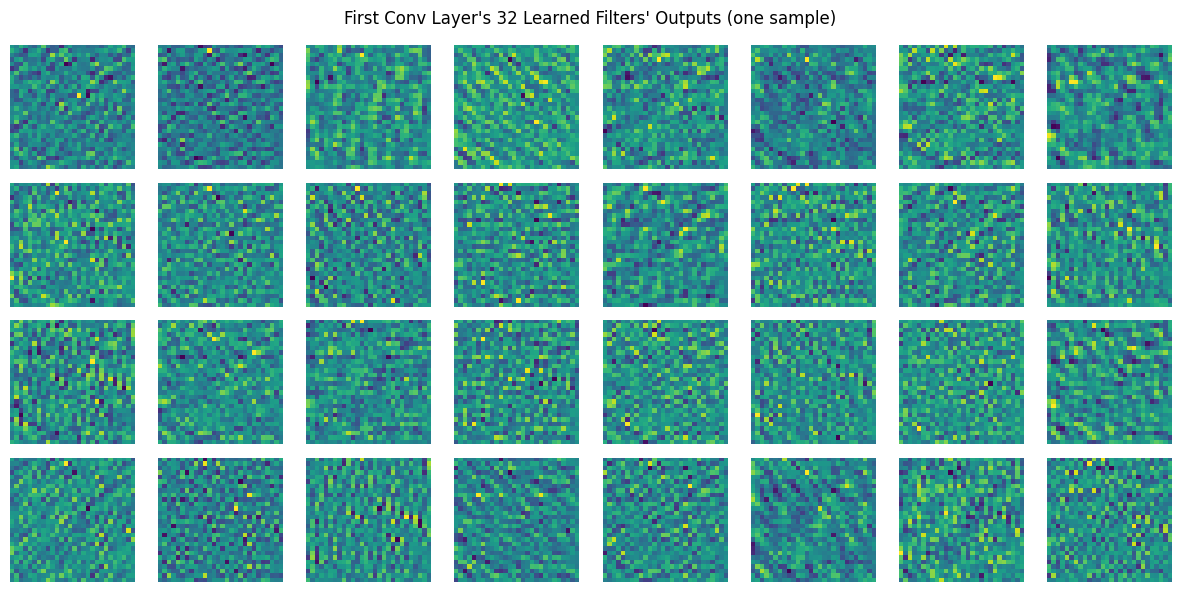

In [ ]:
import matplotlib.pyplot as plt

# Extract and visualize the FIRST conv layer's output feature maps for one sample image --
# a genuinely useful debugging/interpretability technique for CNNs
sample_image = torch.randn(1, 1, 28, 28)   # one sample, illustrative random data

first_conv_layer = model.conv_block1[0]   # index into the Sequential to grab just the Conv2d
with torch.no_grad():
    feature_maps = first_conv_layer(sample_image)   # (1, 32, 28, 28) -- 32 learned filters' outputs

print("Feature maps shape:", feature_maps.shape)

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(feature_maps[0, i].detach().numpy(), cmap="viridis")
    ax.axis("off")
fig.suptitle("First Conv Layer's 32 Learned Filters' Outputs (one sample)")
plt.tight_layout()
plt.show()


### Common Mistakes
- Hardcoding `Linear(64*7*7, 128)`'s input size without actually deriving/verifying it — a very common source of shape-mismatch errors when an architecture is modified (a different number of pooling layers, different input image size) and this hardcoded number isn't updated to match.
- Forgetting `transforms.Normalize` with dataset-appropriate mean/std values — training on raw `[0, 1]`-scaled (or worse, raw `[0, 255]`) pixel values without proper normalization can meaningfully hurt convergence speed and stability.
- Not visualizing intermediate feature maps at all during development — a genuinely useful sanity check (do the filters look like they're detecting something sensible — edges, textures — rather than pure noise, especially after some training?).

### Interview Insight
**Q: You modify a CNN architecture by adding one more pooling layer, and now get a shape-mismatch error in the final `Linear` layer. What's the cause, and how do you fix it correctly (not just by trial and error)?**
A: Adding a pooling layer changes the spatial size flowing out of the convolutional blocks, but the subsequent `Flatten()` + `Linear()`'s hardcoded `in_features` value was calculated for the *previous* architecture's spatial output size — it's now stale and mismatched. The correct fix is to re-derive the new spatial size using Chapter 35's output-size formula (or simply run a forward pass through just the convolutional blocks with a dummy input and check `.shape` directly), then update the `Linear` layer's `in_features` to match — rather than guessing-and-checking, which is error-prone and doesn't build the underlying shape-tracing skill that prevents this class of bug in the first place.

### Exercise
1. Trace, by hand, the exact shape at every stage of `SimpleCNN` for an input of size `(batch=8, 1, 32, 32)` instead of `28x28`, and determine what the final `Linear` layer's `in_features` would need to be.
2. Add a third `conv_block` to `SimpleCNN` and correctly update the classifier's `in_features` to match.

### Quiz (Chapter 36)
1. Trace the exact tensor shape through every layer of `SimpleCNN` from memory.
2. Why must `transforms.Normalize` use dataset-specific mean/std values, not arbitrary ones?
3. What's a genuinely useful sanity check you can perform by visualizing a CNN's first-layer feature maps?


---
# CHAPTER 37 — COMPUTER VISION PIPELINE

## 1. Concept
This chapter formalizes the complete, professional image data pipeline — `torchvision.transforms` for normalization and augmentation, applied correctly and consistently across training vs. evaluation.

## 2. The Full Transform Pipeline


In [ ]:
from torchvision import transforms

# TRAINING transforms -- include RANDOM augmentation (different each epoch, Ch 31's regularization)
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),   # random crop + resize -- viewpoint/scale invariance
    transforms.RandomHorizontalFlip(p=0.5),                   # 50% chance of a left-right flip
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),   # random color variation
    transforms.ToTensor(),                                      # PIL Image -> tensor, scales to [0, 1]
    transforms.Normalize(mean=[0.485, 0.456, 0.406],              # ImageNet's well-known statistics --
                          std=[0.229, 0.224, 0.225]),               # standard for transfer learning (Ch 38)
])

# EVALUATION/TEST transforms -- NO random augmentation -- must be DETERMINISTIC and reproducible
eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),      # a FIXED, deterministic crop -- not random
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

print("Training transform includes RANDOM augmentation (different every epoch).")
print("Evaluation transform is fully DETERMINISTIC -- same result every time, for a fair,")
print("reproducible, and consistent evaluation across runs/checkpoints.")


Training transform includes RANDOM augmentation (different every epoch).
Evaluation transform is fully DETERMINISTIC -- same result every time, for a fair,
reproducible, and consistent evaluation across runs/checkpoints.


### Why Normalization Uses ImageNet's Specific Statistics
`mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]` (one value per RGB channel) are the **empirically measured** per-channel mean/std of the ImageNet dataset — a very large, broad natural-image dataset. When using a model **pretrained on ImageNet** (Chapter 38's transfer learning), you must normalize your own data using these **same** statistics — the pretrained model's early layers learned to expect inputs distributed this specific way, and normalizing your data differently would present it with out-of-distribution input, degrading performance. If training a model **entirely from scratch** on your own dataset, computing your own dataset's actual mean/std (rather than reusing ImageNet's) is technically more appropriate, though using ImageNet's values as a reasonable default is common in practice too.

## 3. Why Training and Evaluation Transforms Must Differ


In [ ]:
print("""
The CRITICAL rule: random augmentation (RandomHorizontalFlip, RandomResizedCrop,
ColorJitter, etc.) belongs ONLY in the TRAINING transform pipeline.

WHY: augmentation's entire PURPOSE is to expose the model to varied, synthetically
diverse versions of each training sample, discouraging exact memorization (Ch 31).
Applying RANDOM transforms at EVALUATION time would make evaluation results
NON-REPRODUCIBLE (a different random crop/flip each time you evaluate the SAME
model on the SAME data would give a DIFFERENT accuracy number each run) -- this
would make it impossible to reliably compare two model checkpoints, or to trust
any single evaluation number as representative.

Evaluation transforms should be the MINIMAL, DETERMINISTIC preprocessing needed
to get the image into the correct size/format/normalization the model expects --
nothing more.
""")



The CRITICAL rule: random augmentation (RandomHorizontalFlip, RandomResizedCrop,
ColorJitter, etc.) belongs ONLY in the TRAINING transform pipeline.

WHY: augmentation's entire PURPOSE is to expose the model to varied, synthetically
diverse versions of each training sample, discouraging exact memorization (Ch 31).
Applying RANDOM transforms at EVALUATION time would make evaluation results
NON-REPRODUCIBLE (a different random crop/flip each time you evaluate the SAME
model on the SAME data would give a DIFFERENT accuracy number each run) -- this
would make it impossible to reliably compare two model checkpoints, or to trust
any single evaluation number as representative.

Evaluation transforms should be the MINIMAL, DETERMINISTIC preprocessing needed
to get the image into the correct size/format/normalization the model expects --
nothing more.



### A Complete Custom `Dataset` Using These Transforms


In [ ]:
from torch.utils.data import Dataset
# from PIL import Image

class ImageClassificationDataset(Dataset):
    def __init__(self, image_paths: list, labels: list, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform   # EITHER train_transform OR eval_transform, chosen by the CALLER

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # image = Image.open(self.image_paths[idx]).convert("RGB")
        # if self.transform:
        #     image = self.transform(image)
        # return image, self.labels[idx]
        placeholder = torch.randn(3, 224, 224)   # illustrative, since no real files exist here
        return placeholder, self.labels[idx]


image_paths = [f"/data/img_{i}.jpg" for i in range(500)]
labels = [i % 10 for i in range(500)]

train_paths, val_paths = image_paths[:400], image_paths[400:]
train_labels, val_labels = labels[:400], labels[400:]

train_dataset = ImageClassificationDataset(train_paths, train_labels, transform=train_transform)
val_dataset = ImageClassificationDataset(val_paths, val_labels, transform=eval_transform)   # DIFFERENT transform!

print("Train dataset uses train_transform (WITH augmentation)")
print("Val dataset uses eval_transform (deterministic, NO augmentation)")
print("\nThis distinction -- same Dataset CLASS, DIFFERENT transform objects passed in --")
print("is the standard, correct pattern for train/val split handling in computer vision.")


Train dataset uses train_transform (WITH augmentation)
Val dataset uses eval_transform (deterministic, NO augmentation)

This distinction -- same Dataset CLASS, DIFFERENT transform objects passed in --
is the standard, correct pattern for train/val split handling in computer vision.


### Common Mistakes
- Using the same (augmented) transform pipeline for both training and evaluation — makes evaluation non-reproducible and can make reported metrics look artificially worse or inconsistent run to run.
- Using arbitrary/mismatched normalization statistics when using a pretrained model — must match exactly what the pretrained model was originally trained with (typically ImageNet's statistics), or performance degrades.
- Applying augmentation that isn't actually appropriate for the task/domain (e.g., `RandomHorizontalFlip` on images of text or on medical images where left-right orientation is diagnostically meaningful) — augmentation choices should be domain-informed, not applied reflexively.

### Interview Insight
**Q: Why must your evaluation/test transform pipeline never include random augmentation, even though it's essential for the training pipeline?**
A: Random augmentation's purpose during training is to expose the model to varied versions of each sample, discouraging memorization and improving generalization — a genuinely useful randomness. But at evaluation time, the goal is a reliable, reproducible measurement of the model's actual performance; if evaluation included random transforms, running the exact same evaluation twice on the exact same model and data could produce two different accuracy numbers purely due to which random crop/flip happened to be applied each time — making it impossible to trust any single evaluation result, compare model checkpoints fairly, or reliably detect genuine performance changes versus mere evaluation noise. Evaluation transforms should be the minimal, fully deterministic preprocessing needed to match the model's expected input format.

### Exercise
1. Build a `train_transform` and `eval_transform` pair for a grayscale (single-channel) image dataset, correctly adjusting the `Normalize` call's mean/std to single values instead of RGB triples.
2. Explain, in a markdown note, why `CenterCrop` (deterministic) replaces `RandomResizedCrop` (random) specifically in the evaluation pipeline.

### Quiz (Chapter 37)
1. Why must random augmentation be excluded from evaluation transforms?
2. Why do ImageNet's specific mean/std values matter when using a pretrained model?
3. What's the correct pattern for using the same `Dataset` class with different transforms for train vs. validation splits?


---
# CHAPTER 38 — TRANSFER LEARNING

## 1. Concept
Transfer learning reuses a model **already trained** on a large, general dataset (typically ImageNet, ~1.2 million images, 1000 classes) as a starting point for a **new, often much smaller** task — dramatically reducing the data and compute needed to reach strong performance, since the pretrained model's early/middle layers have already learned broadly useful visual features (edges, textures, shapes) that transfer well across many different vision tasks.

## 2. The Standard Workflow
```
Pretrained Model
     ↓
Freeze Backbone (prevent its already-learned weights from changing initially)
     ↓
Replace Classifier (swap the final layer for one matching YOUR number of classes)
     ↓
Train Head (only the new final layer's weights update, backbone stays frozen)
     ↓
Fine-Tune Backbone (OPTIONAL: unfreeze some/all backbone layers, continue training
                      at a MUCH LOWER learning rate)
```

## 3. Loading a Pretrained Model and Freezing the Backbone


In [ ]:
from torchvision import models

# Loading a pretrained ResNet18 (Chapter 39 covers ResNet's architecture itself in depth) --
# weights="IMAGENET1K_V1" downloads pretrained ImageNet weights (illustrative here -- requires
# internet access this sandbox doesn't have)
model = models.resnet18(weights="IMAGENET1K_V1")

# STEP 1: freeze the ENTIRE backbone -- prevent gradient updates to already-learned weights
for param in model.parameters():
    param.requires_grad = False

print("All backbone parameters frozen (requires_grad=False) -- Chapter 13's lesson,")
print("applied here specifically to PREVENT gradient tracking/updates for these weights.")

# STEP 2: replace the FINAL classification layer -- ResNet18's original final layer
# (model.fc) outputs 1000 classes (ImageNet's); we need it to output OUR number of classes
num_our_classes = 10
model.fc = torch.nn.Linear(model.fc.in_features, num_our_classes)

print(f"\nReplaced final layer: now outputs {num_our_classes} classes instead of 1000.")
print("CRITICALLY: a freshly-created nn.Linear layer's parameters default to requires_grad=True --")
print("so ONLY this new final layer will actually be trained; everything else stays frozen.")

# Verify: count trainable vs frozen parameters
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen = sum(p.numel() for p in model.parameters() if not p.requires_grad)
print(f"\nTrainable parameters: {trainable:,}")
print(f"Frozen parameters: {frozen:,}")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 115MB/s]

All backbone parameters frozen (requires_grad=False) -- Chapter 13's lesson,
applied here specifically to PREVENT gradient tracking/updates for these weights.

Replaced final layer: now outputs 10 classes instead of 1000.
CRITICALLY: a freshly-created nn.Linear layer's parameters default to requires_grad=True --
so ONLY this new final layer will actually be trained; everything else stays frozen.

Trainable parameters: 5,130
Frozen parameters: 11,176,512


### Line-by-Line Explanation
- `param.requires_grad = False` for every parameter — directly reuses Chapter 13's autograd mechanism: a frozen parameter still participates in the **forward** pass normally (contributing to the model's computation), but no gradient is computed for it during `.backward()`, and the optimizer (even if given this parameter) would never update it.
- `model.fc = torch.nn.Linear(...)` — replacing an attribute on an already-constructed `nn.Module` works exactly as Chapter 16 described: this triggers `nn.Module`'s special `__setattr__`, correctly re-registering `fc` as the (new) submodule, replacing the old one entirely.
- The **new** `fc` layer's parameters are `requires_grad=True` by default (freshly created tensors are, unless explicitly set otherwise) — so freezing happened *before* replacing the layer specifically so the replacement is unaffected, ending up trainable while everything else remains frozen.

## 4. Feature Extraction vs. Fine-Tuning — When to Unfreeze


In [ ]:
# Only optimize parameters that ACTUALLY require gradients -- filtering is essential,
# since passing FROZEN parameters to an optimizer is harmless but wasteful
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),   # only the new fc layer's params
    lr=1e-3,
)
print("Optimizer created with ONLY the trainable (unfrozen) parameters.")

# LATER, after the new head has trained for a while and performance has plateaued:
# unfreeze the LAST FEW backbone layers for fine-tuning, at a MUCH LOWER learning rate
for name, param in model.named_parameters():
    if "layer4" in name:   # ResNet's naming convention -- layer4 is its LAST/deepest block
        param.requires_grad = True

fine_tune_optimizer = torch.optim.AdamW([
    {"params": model.fc.parameters(), "lr": 1e-3},        # the (already-trained) head: normal LR
    {"params": model.layer4.parameters(), "lr": 1e-5},     # the newly-unfrozen backbone layers: MUCH lower LR
])
print("\nFine-tuning optimizer uses DIFFERENT learning rates for different parameter groups --")
print("the newly-unfrozen backbone layers get a MUCH smaller LR to avoid catastrophically")
print("destroying their already-useful pretrained features with large, disruptive updates.")


Optimizer created with ONLY the trainable (unfrozen) parameters.

Fine-tuning optimizer uses DIFFERENT learning rates for different parameter groups --
the newly-unfrozen backbone layers get a MUCH smaller LR to avoid catastrophically
destroying their already-useful pretrained features with large, disruptive updates.


### Why Fine-Tuning Uses a Much Lower Learning Rate
The backbone's pretrained weights already encode genuinely useful, well-trained features — a large learning rate applied to them (the same LR reasonable for a freshly-initialized new layer) risks **catastrophic forgetting**: large, disruptive gradient updates that destroy the useful pretrained representations before the model has a chance to productively adapt them to the new task. A much smaller learning rate for unfrozen backbone layers (often 10-100x smaller than the new head's LR, exactly as shown above via `param_groups`) allows gentle, incremental adaptation instead.

### Feature Extraction vs. Fine-Tuning — Choosing Based on Your Dataset
| Your new dataset is... | Recommended approach |
|---|---|
| Small, similar to ImageNet's domain (natural photos) | Feature extraction only (freeze backbone entirely, train just the new head) — less risk of overfitting a small dataset by also fine-tuning many backbone parameters |
| Large, similar to ImageNet's domain | Fine-tune more of the backbone — enough data to safely adapt more parameters without overfitting |
| Small, very different from ImageNet's domain (e.g., medical imaging, satellite imagery) | Fine-tune cautiously, at a very low LR, and closely monitor validation performance — pretrained features may transfer less well, but full from-scratch training risks not having enough data |
| Large, very different domain | Fine-tune extensively, or consider training from scratch if data is truly abundant |

### Common Mistakes
- Forgetting to freeze the backbone before replacing the final layer — if optimizer is given `model.parameters()` (all of them) without first freezing, the entire pretrained backbone gets updated by potentially-large early gradients from the freshly-initialized (and thus initially very wrong) new final layer, risking catastrophic forgetting from the very first training step.
- Using the same learning rate for newly-unfrozen backbone layers as for a freshly-initialized head — directly risks catastrophic forgetting, as explained above.
- Passing frozen parameters to the optimizer unnecessarily — harmless (they never update, since gradients are never computed for them) but wasteful; filtering to only `requires_grad=True` parameters, as shown, is the cleaner, standard pattern.
- Not matching normalization statistics (Chapter 37) to what the pretrained model actually expects — using different mean/std values presents the pretrained backbone with data distributed differently than what it learned on, degrading transfer performance.

### Interview Insight
**Q: You're fine-tuning a pretrained ResNet on a new, small dataset and want to unfreeze the last few backbone layers. Why should these unfrozen layers use a much lower learning rate than the newly-added classification head?**
A: The unfrozen backbone layers already contain well-trained, genuinely useful feature representations learned from a large pretraining dataset (typically ImageNet) — applying a large learning rate to them risks catastrophic forgetting: big, disruptive gradient updates (especially early in fine-tuning, when the new head's gradients can be large and somewhat noisy since it started randomly initialized) that destroy these useful pretrained features before the model has a chance to gently adapt them. The newly-added head, by contrast, starts from random initialization and genuinely needs larger updates to learn anything useful at all. Using PyTorch's per-parameter-group learning rates (`optimizer.param_groups`), you give the head a normal learning rate while giving the unfrozen backbone layers a much smaller one (often 10-100x smaller), allowing careful, incremental adaptation of the pretrained features rather than disruptive overwriting.

### Exercise
1. Load a pretrained model (conceptually, if you can't download weights in your environment), freeze its backbone, replace its final classification layer for a 5-class problem, and verify (via the trainable/frozen parameter count check) that only the new layer is trainable.
2. Set up a fine-tuning optimizer with two parameter groups (head and last backbone block) using different learning rates, and explain your chosen LR ratio.

### Quiz (Chapter 38)
1. Walk through the full transfer learning workflow, in order.
2. Why must you freeze the backbone BEFORE replacing the final layer, not after?
3. What is "catastrophic forgetting," and how does using a lower learning rate for unfrozen backbone layers prevent it?
4. How would you decide whether to use pure feature extraction versus full fine-tuning for a given new dataset?

### Chapter 38 Summary
- Transfer learning reuses pretrained visual features, dramatically reducing the data/compute needed for a new vision task.
- The standard workflow: freeze backbone → replace final layer → train the new head → optionally fine-tune some backbone layers at a much lower learning rate.
- Choice of feature-extraction-only vs. full fine-tuning depends on your new dataset's size and similarity to the pretraining domain.

---

## END OF NOTEBOOK 7 — What You Should Now Be Able To Do
- Read and diagnose the four classic learning curve patterns, and use gradient norm diagnostics to investigate vanishing/exploding gradients.
- Systematically debug the most common PyTorch training failures using this course's consolidated reference table.
- Set up TensorBoard experiment tracking, logging metrics and hyperparameters correctly for later comparison.
- Explain and apply CNN fundamentals: convolution's output-size formula, pooling (including `AdaptiveAvgPool2d`), and receptive field growth with depth.
- Build, trace shapes through, and train a complete CNN from scratch, and visualize its learned feature maps.
- Build a correct computer vision pipeline with `torchvision.transforms`, correctly separating training (augmented) from evaluation (deterministic) preprocessing.
- Apply transfer learning correctly: freeze → replace → train head → fine-tune with per-layer-group learning rates, and explain catastrophic forgetting.

## Before Moving to Notebook 8 (Chapters 39–45: Modern CNN Architectures, Image Classification Project, Object Detection, Image Segmentation, Sequence Models, RNN From Scratch, LSTM)
